## Simple Parallel workflow in Lang Grapgh
Make the workflow
- Input :-
    - Runs
    - Balls
    - 4s
    - 6s
- Output :-
    - Strick rate
    - Run in boundary percentage
    - Ball per boundary

### Nodes and Edges are connected as:-
```text
              | - strict_rate          - |
|START| ----> | - boundary_percentage  - | ----> |Summary| ----> END
              | - boundary_per_ball    - |
```

In [23]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [16]:
class BatmanState(TypedDict):
    run : int
    ball : int
    fours : int
    sixs : int

    strick_rate : float
    boundary_percentage : float
    ball_per_boundary : float
    summary : str

`Note:` Rather then sending entir state we only return(send) partial state
`instead` of this return state
`we using ` {'strick_rate' : strick_rate}
`State is type of dictinary we send partail dictinary`

- we have to always try to return partial state in every workflow

In [17]:
def calculate_strick_rate(state: BatmanState):
    
    strick_rate = (state['run']/state['ball'])*100
    
    return {'strick_rate':strick_rate}

In [18]:
def calculate_ball_per_boundary(state:BatmanState):
    
    ball_per_boundary = state['ball']/(state['fours'] + state['sixs'])
    
    return {'ball_per_boundary':ball_per_boundary}

In [19]:
def calculate_boundary_percentage(state: BatmanState):
    
    boundary_percentage = (((4 * state['fours']) + (6*state['sixs']) )/state['run'])*100
    
    return {'boundary_percentage': boundary_percentage}

In [20]:
def summary(state: BatmanState):
    
    summary = f"""Summary:
    - Run: {state['run']} \n
    - Ball: {state['ball']} \n
    - Strike Rate: {state['strick_rate']}% \n
    - Ball per Boundary: {state['ball_per_boundary']}\n
    - Boundary Percentage: {state['boundary_percentage']}%"""
    
    return {'summary': summary}

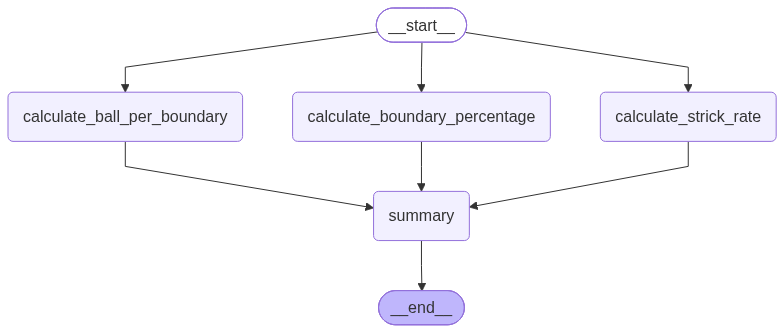

In [21]:
graph = StateGraph(BatmanState)

# adding nodes
graph.add_node('calculate_strick_rate', calculate_strick_rate)
graph.add_node('calculate_boundary_percentage',calculate_boundary_percentage )
graph.add_node('calculate_ball_per_boundary',calculate_ball_per_boundary)
graph.add_node('summary',summary)


# adding edges
graph.add_edge(START,'calculate_strick_rate')
graph.add_edge(START,'calculate_boundary_percentage')
graph.add_edge(START,'calculate_ball_per_boundary')

graph.add_edge('calculate_strick_rate','summary')
graph.add_edge('calculate_boundary_percentage','summary')
graph.add_edge('calculate_ball_per_boundary','summary')

graph.add_edge('summary',END)

# compile
workflow = graph.compile()
workflow

In [22]:
initial_state = {
    'run' : 100,
    'ball' : 60,
    'fours' : 10,
    'sixs' : 5
}

workflow.invoke(initial_state)

{'run': 100,
 'ball': 60,
 'fours': 10,
 'sixs': 5,
 'strick_rate': 166.66666666666669,
 'boundary_percentage': 70.0,
 'ball_per_boundary': 4.0,
 'summary': 'Summary:\n    - Run: 100 \n\n    - Ball: 60 \n\n    - Strike Rate: 166.66666666666669% \n\n    - Ball per Boundary: 4.0\n\n    - Boundary Percentage: 70.0%'}